In [1]:

from google.colab import files

uploaded = files.upload()

Saving dataset-resized.zip to dataset-resized.zip


In [2]:
import zipfile
import os

zip_file = next(iter(uploaded))

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/waste_dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
dataset_path = '/content/waste_dataset/dataset-resized'
print(os.listdir(dataset_path))

['metal', 'glass', 'plastic', 'paper', 'trash', 'cardboard', '.DS_Store']


In [4]:
#Counting Images
import os

dataset_path = '/content/waste_dataset/dataset-resized'

for category in os.listdir(dataset_path):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path) and not category.startswith('.'):
        images = os.listdir(category_path)
        print(category, ":", len(images), "images")

metal : 410 images
glass : 501 images
plastic : 482 images
paper : 594 images
trash : 137 images
cardboard : 403 images


In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=42
)

val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=42,
    shuffle=False
)

print("Class labels:", train_data.class_indices)

Found 2024 images belonging to 6 classes.
Found 503 images belonging to 6 classes.
Class labels: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [7]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential

# Load pre-trained MobileNetV2
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pre-trained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully!


In [8]:
model = Sequential([
    base_model,

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(6, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.6789 - loss: 0.8831 - val_accuracy: 0.7435 - val_loss: 0.6848
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.8439 - loss: 0.4408 - val_accuracy: 0.7356 - val_loss: 0.6893
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.8888 - loss: 0.3074 - val_accuracy: 0.7714 - val_loss: 0.6202
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9185 - loss: 0.2439 - val_accuracy: 0.7455 - val_loss: 0.6699
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9452 - loss: 0.1779 - val_accuracy: 0.7714 - val_loss: 0.5711
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9639 - loss: 0.1303 - val_accuracy: 0.7833 - val_loss: 0.5959
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9704 - loss: 0.1048 - val_accuracy: 0.7833 - val_loss: 0.6183
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.9802 - loss: 0.0849 - val_accuracy: 0.7773 - v

In [10]:
# Unfreeze the MobileNetV2 base model
base_model.trainable = True

# Keep most layers frozen; train only the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Use a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning setup completed!")

Fine-tuning setup completed!


In [11]:
history_fine = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.8814 - loss: 0.3163 - val_accuracy: 0.7813 - val_loss: 0.6731
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9244 - loss: 0.2143 - val_accuracy: 0.7913 - val_loss: 0.6462
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.9452 - loss: 0.1698 - val_accuracy: 0.7972 - val_loss: 0.6419
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.9521 - loss: 0.1439 - val_accuracy: 0.7972 - val_loss: 0.6405
Epoch 5/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.9605 - loss: 0.1222 - val_accuracy: 0.8032 - val_loss: 0.6405


In [12]:
import json
model.save('/content/waste_classifier.keras')

print("MobileNetV2 model saved successfully!")

class_labels = list(train_data.class_indices.keys())

with open('/content/class_labels.json', 'w') as f:
    json.dump(class_labels, f)

print("Final MobileNetV2 model saved successfully!")
print("Class labels saved successfully!")
print(class_labels)

MobileNetV2 model saved successfully!
Final MobileNetV2 model saved successfully!
Class labels saved successfully!
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [13]:
best_model = tf.keras.models.load_model(
    '/content/waste_classifier.keras'
)

val_loss, val_accuracy = best_model.evaluate(val_data)

print("Final Validation Accuracy:",
      round(val_accuracy * 100, 2), "%")

print("Final Validation Loss:",
      round(val_loss, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8032 - loss: 0.6405
Final Validation Accuracy: 80.32 %
Final Validation Loss: 0.6405


In [14]:
import numpy as np
from sklearn.metrics import classification_report

predictions = best_model.predict(val_data)

y_pred = np.argmax(predictions, axis=1)
y_true = val_data.classes

class_names = list(val_data.class_indices.keys())

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step
              precision    recall  f1-score   support

   cardboard       0.95      0.76      0.85        80
       glass       0.78      0.84      0.81       100
       metal       0.75      0.82      0.78        82
       paper       0.84      0.92      0.88       118
     plastic       0.79      0.72      0.75        96
       trash       0.56      0.56      0.56        27

    accuracy                           0.80       503
   macro avg       0.78      0.77      0.77       503
weighted avg       0.81      0.80      0.80       503



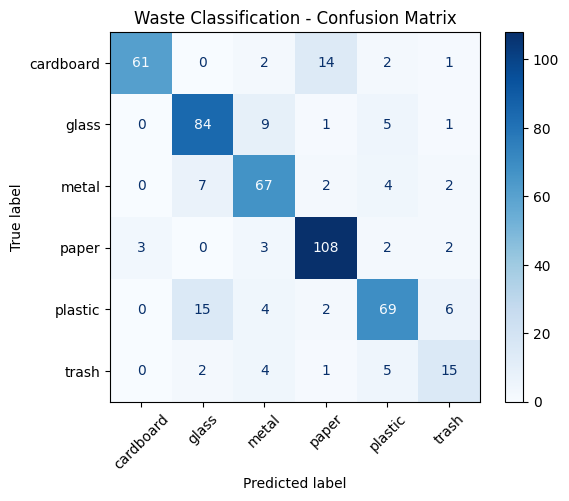

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(cmap='Blues', xticks_rotation=45)
plt.title("Waste Classification - Confusion Matrix")
plt.show()

In [28]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))
print("Uploaded:", image_path)

Saving Crushed plastic water bottle isolated on transparent background, waste recycling pollution plastic concept_ Stock Photo _ Adobe Stock.jpeg to Crushed plastic water bottle isolated on transparent background, waste recycling pollution plastic concept_ Stock Photo _ Adobe Stock (2).jpeg
Uploaded: Crushed plastic water bottle isolated on transparent background, waste recycling pollution plastic concept_ Stock Photo _ Adobe Stock (2).jpeg


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


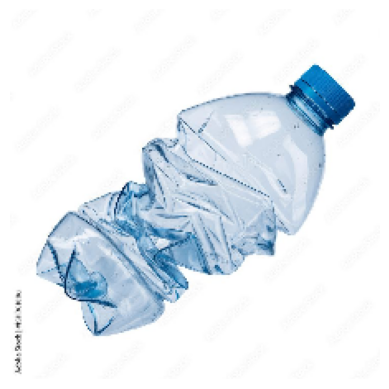

Predicted Category: plastic
Confidence: 99.66 %


In [29]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

img = image.load_img(image_path, target_size=(224, 224))

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

prediction = best_model.predict(img_array)

predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

plt.imshow(img)
plt.axis('off')
plt.show()

print("Predicted Category:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

In [30]:
recycling_suggestions = {
    'cardboard': 'Keep dry and send it for paper recycling.',
    'glass': 'Separate carefully and send it to a glass recycling facility.',
    'metal': 'Separate metal items for metal recycling.',
    'paper': 'Keep clean and dry for paper recycling.',
    'plastic': 'Check the plastic type and local recycling guidelines.',
    'trash': 'Check local waste disposal guidelines.'
}

print("Predicted Category:", predicted_class)
print("Confidence:", round(confidence, 2), "%")
print("Recycling Suggestion:",
      recycling_suggestions[predicted_class])

Predicted Category: plastic
Confidence: 99.66 %
Recycling Suggestion: Check the plastic type and local recycling guidelines.


In [19]:
best_model = tf.keras.models.load_model(
    '/content/waste_classifier.keras'
)

In [20]:
import os

print(os.listdir('/content'))

['.config', 'dataset-resized.zip', 'waste_dataset', 'waste_classifier.keras', 'Crushed plastic water bottle isolated on transparent background, waste recycling pollution plastic concept_ Stock Photo _ Adobe Stock.jpeg', 'class_labels.json', 'sample_data']


In [21]:
from google.colab import files

files.download('/content/waste_classifier.keras')
files.download('/content/class_labels.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving waste_classifier.keras to waste_classifier (2).keras
Saving class_labels.json to class_labels (2).json
Model loaded successfully!
Labels loaded successfully!


In [27]:
from google.colab import files
import tensorflow as tf
import json

uploaded = files.upload()

model_file = next(
    name for name in uploaded if name.endswith('.keras')
)

labels_file = next(
    name for name in uploaded if name.endswith('.json')
)

best_model = tf.keras.models.load_model(model_file)

with open(labels_file, 'r') as f:
    class_labels = json.load(f)

class_names = class_labels

print("Model loaded successfully!")
print("Labels loaded successfully!")

Saving waste_classifier.keras to waste_classifier (3).keras
Saving class_labels.json to class_labels (3).json
Model loaded successfully!
Labels loaded successfully!
